An overview of the datasets of the benchmark: how many cells, genes and classes each has, how sparse it is,
which species and tissue it comes from, and how its cells and classes are distributed.

# Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

from src import paths
from src.constants import PROJECT_ROOT
from src.data_loading import load_csv_data, load_ground_truth_labels
from src.dataset_config import VALID_SPECIES, load_dataset_config, parse_species

In [2]:
# The datasets the workflow runs on
with open(PROJECT_ROOT / 'config' / 'config.yaml') as f:
    DATASETS = yaml.safe_load(f)['datasets']

## Data Loading

Each count matrix is loaded once and reduced to its summary statistics, so that only one matrix is in memory
at a time. This takes a minute or two, mostly for the two ~4,000-cell 10x datasets.

In [3]:
summaries = []
per_cell = []
class_sizes = {}

for accession in DATASETS:
    config = load_dataset_config(paths.resolve(paths.DATASET_CONFIG, accession=accession))
    counts = load_csv_data(paths.resolve(paths.RAW_COUNTS, accession=accession))
    species = parse_species(config)
    labels = load_ground_truth_labels(paths.resolve(paths.GROUND_TRUTH_LABELS, accession=accession))

    values = counts.to_numpy()
    detected = values > 0
    total_counts = values.sum(axis=1)
    genes_per_cell = detected.sum(axis=1)
    sizes = labels.value_counts()

    summaries.append({
        'Dataset': accession,
        'Species': species,
        'Tissue': config.get('tissue', ''),
        'Protocol': config.get('protocol', ''),
        'Cells': counts.shape[0],
        'Genes': counts.shape[1],
        'Genes detected': int(detected.any(axis=0).sum()),
        'Classes': labels.nunique(),
        'Sparsity (%)': 100 * (1 - detected.mean()),
        'Median counts / cell': np.median(total_counts),
        'Median genes / cell': np.median(genes_per_cell),
        'Imbalance (largest / smallest)': sizes.max() / sizes.min(),
    })
    per_cell.append(pd.DataFrame({
        'Dataset': accession,
        'Species': species,
        'total_counts': total_counts,
        'genes_detected': genes_per_cell,
    }))
    class_sizes[accession] = sizes

    del counts, values, detected

summary = pd.DataFrame(summaries).set_index('Dataset')
per_cell = pd.concat(per_cell, ignore_index=True)

# Overview

`Genes` is every gene in the count matrix, `Genes detected` those with a count in at least one cell.
`Sparsity` is the fraction of zero entries. `Imbalance` is the size of the largest class over the smallest
(1 means balanced classes).

In [4]:
summary.style.format({
    'Cells': '{:,}',
    'Genes': '{:,}',
    'Genes detected': '{:,}',
    'Sparsity (%)': '{:.1f}',
    'Median counts / cell': '{:,.0f}',
    'Median genes / cell': '{:,.0f}',
    'Imbalance (largest / smallest)': '{:.1f}',
})

,Species,Tissue,Protocol,Cells,Genes,Genes detected,Classes,Sparsity (%),Median counts / cell,Median genes / cell,Imbalance (largest / smallest)
Dataset,,,,,,,,,,,
E-MTAB-3321,mouse,Preimplantation embryo,Smart-Seq2,124,"41,480","28,223",5,68.6,"1,322,816","13,274",10.7
E-MTAB-2805,mouse,Embryonic stem cells,SMARTer (Fluidigm C1),288,"38,293","28,010",3,74.4,"2,671,027","10,157",1.0
GSE36552,human,Preimplantation embryo,Tang,124,"20,286","20,286",8,37.7,"17,798,590","12,706",11.3
GSE45719,mouse,Preimplantation embryo,Smart-seq,268,"22,431","21,299",10,60.3,"9,234,726","8,622",15.0
GSE60781,mouse,Bone marrow,SMARTer (Fluidigm C1),251,"29,863","15,752",3,86.6,"655,060","3,951",1.6
GSE118767_10x_5cl,human,Lung cancer cell lines,10x Chromium,"3,822","32,895","32,606",5,85.9,"25,327","4,700",2.9
GSE118767_celseq2_3cl,human,Lung cancer cell lines,CEL-seq2,240,"28,142","27,622",3,74.1,"37,300","7,547",1.5
GSE118767_dropseq_3cl,human,Lung cancer cell lines,Drop-seq,210,"31,253","26,217",3,80.6,"23,182","5,800",1.2
zheng_pbmc_bead_enriched,human,Blood (PBMC),10x GemCode,"3,774","16,791","16,791",10,95.7,"1,512",594,4.7


## Per dataset distributions

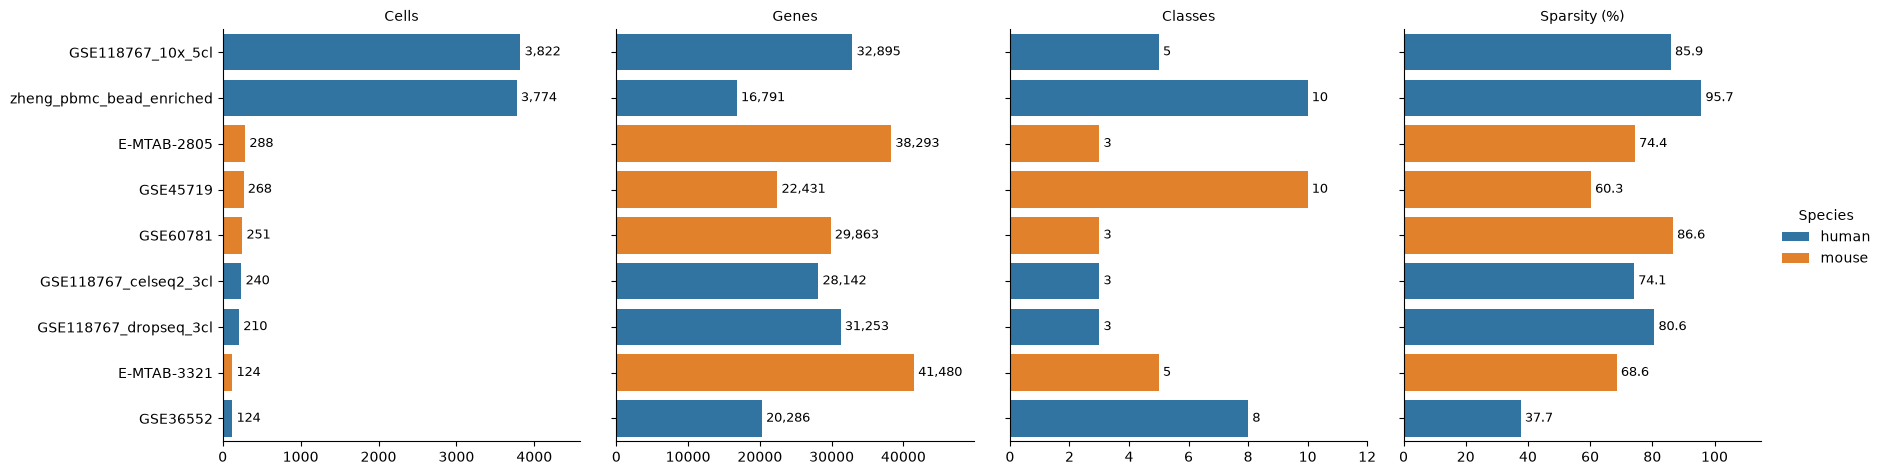

In [5]:
metrics = summary.reset_index().melt(
    id_vars=['Dataset', 'Species'],
    value_vars=['Cells', 'Genes', 'Classes', 'Sparsity (%)'],
    var_name='Metric',
    value_name='Value',
)

g = sns.catplot(
    data=metrics,
    y='Dataset',
    x='Value',
    hue='Species',
    hue_order=VALID_SPECIES,  # same color for each species in every plot
    col='Metric',
    kind='bar',
    order=summary.sort_values('Cells', ascending=False).index,
    sharex=False,
    height=0.45 * len(summary) + 1,
    aspect=0.9,
)

formats = {'Cells': '{:,.0f}', 'Genes': '{:,.0f}', 'Classes': '{:.0f}', 'Sparsity (%)': '{:.1f}'}
for metric, ax in g.axes_dict.items():
    for container in ax.containers:
        ax.bar_label(container, fmt=formats[metric], padding=3, fontsize=9)
    ax.margins(x=0.2)

g.set_axis_labels('', '')
g.set_titles('{col_name}')
plt.show()

# Cells

Library size (total counts) and the number of detected genes of each cell. Full-length, plate-based protocols
(Smart-seq, SMARTer, Tang) sequence each cell far deeper than the droplet ones (10x, Drop-seq), which is where
most of the difference in sparsity comes from.

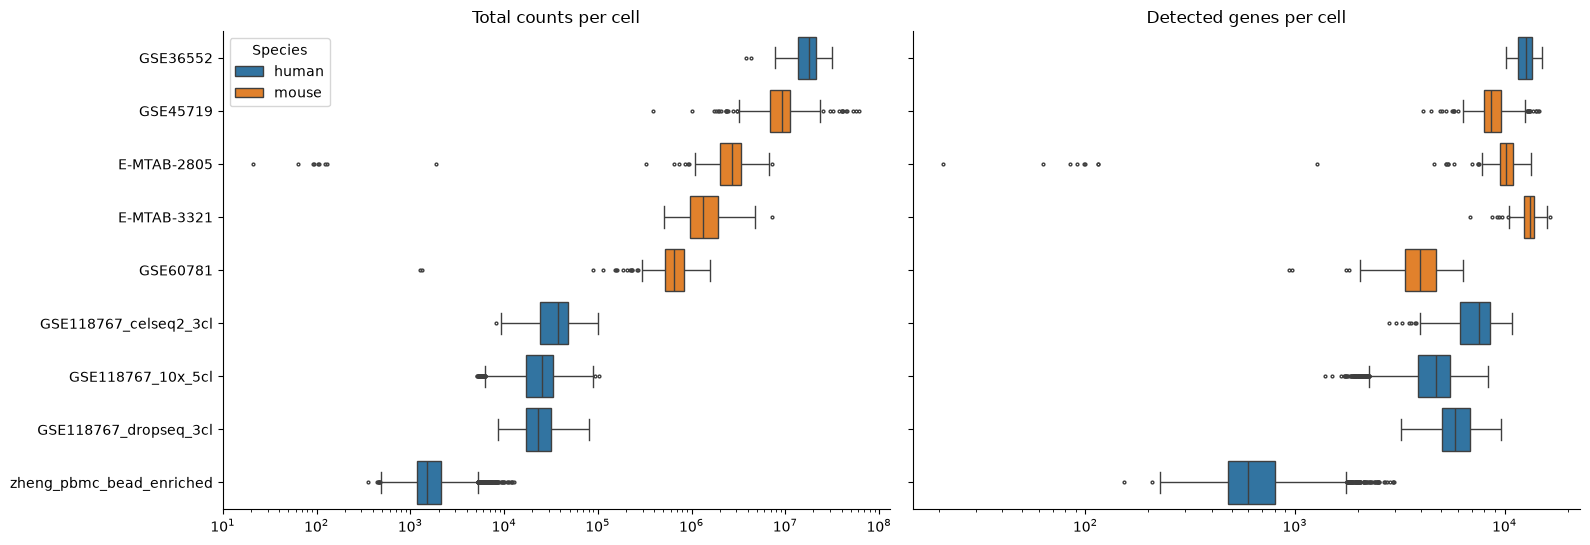

In [6]:
order = summary.sort_values('Median counts / cell', ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(16, 0.45 * len(order) + 1.5), sharey=True)

for ax, (column, title) in zip(axes, [
    ('total_counts', 'Total counts per cell'),
    ('genes_detected', 'Detected genes per cell'),
]):
    sns.boxplot(
        data=per_cell,
        x=column,
        y='Dataset',
        hue='Species',
        hue_order=VALID_SPECIES,  # same color for each species in every plot
        order=order,
        log_scale=True,
        fliersize=2,
        legend=ax is axes[0],
        ax=ax,
    )
    ax.set(title=title, xlabel='', ylabel='')

sns.despine(fig)
fig.tight_layout()
plt.show()

# Classes

The size of each ground truth class. Imbalanced classes are harder for algorithms that favor clusters of
similar size (e.g. k-means), and small classes are easy to merge into a larger neighbor.

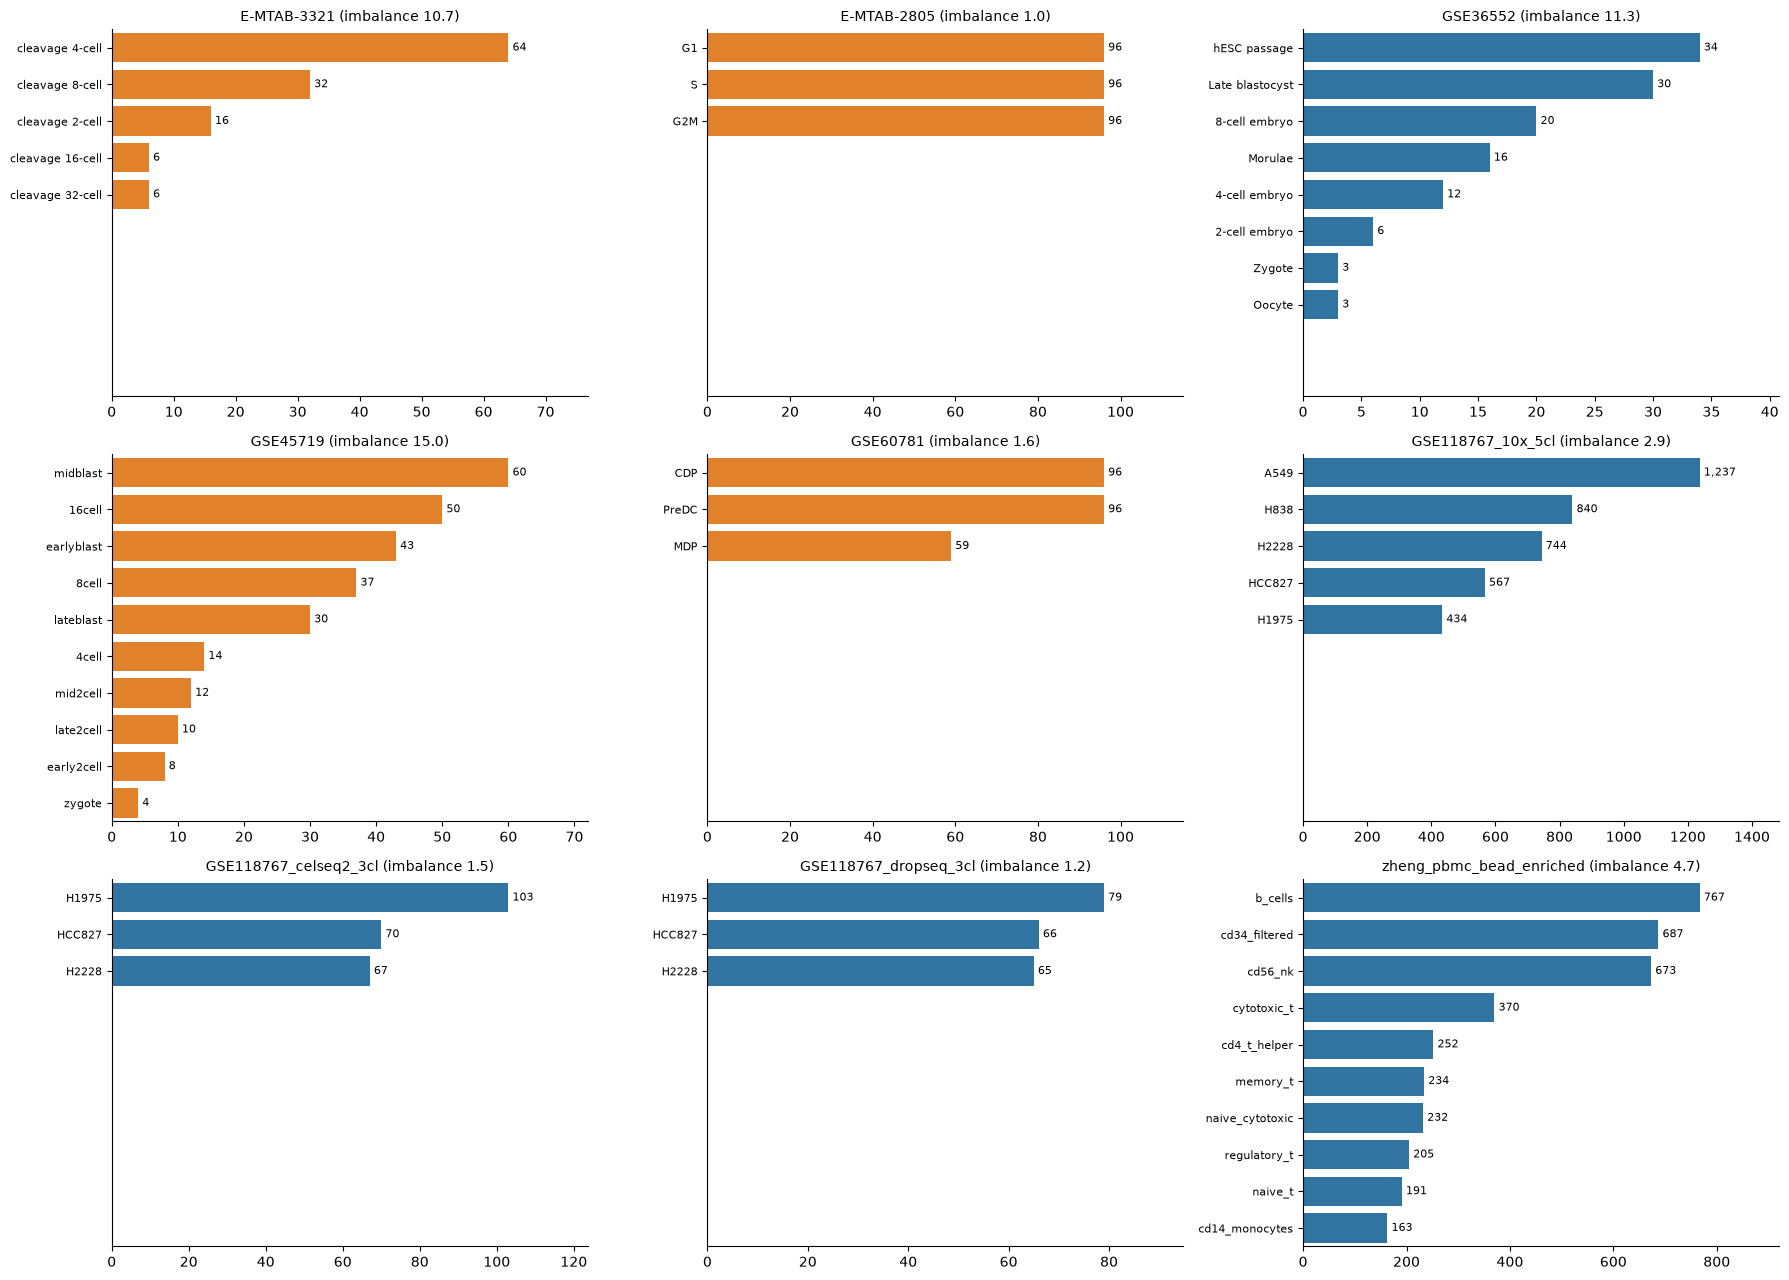

In [7]:
n_cols = 3
n_rows = int(np.ceil(len(DATASETS) / n_cols))
max_classes = summary['Classes'].max()
colors = dict(zip(VALID_SPECIES, sns.color_palette()))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 0.28 * max_classes * n_rows + 1.5 * n_rows))
axes = axes.flatten()

for ax, accession in zip(axes, DATASETS):
    sizes = class_sizes[accession]  # largest first
    sns.barplot(x=sizes.values, y=sizes.index.astype(str), color=colors[summary.loc[accession, 'Species']], ax=ax)
    ax.bar_label(ax.containers[0], fmt='{:,.0f}', padding=3, fontsize=8)
    ax.margins(x=0.2)
    # Same bar thickness in every panel, largest class on top
    ax.set_ylim(max_classes - 0.5, -0.5)
    ax.set_title(f'{accession} (imbalance {summary.loc[accession, "Imbalance (largest / smallest)"]:.1f})', fontsize=10)
    ax.set(xlabel='', ylabel='')
    ax.tick_params(axis='y', labelsize=8)
for ax in axes[len(DATASETS):]:
    ax.set_visible(False)

sns.despine(fig)
fig.tight_layout()
plt.show()

# Observations

- **Size:** seven datasets have 124 to 288 cells; only the 10x CellBench and the bead-enriched PBMCs have
  thousands (~3,800 each).
- **Classes:** 3 to 10 classes. The cell cycle (E-MTAB-2805), DC progenitor (GSE60781) and 3-cell-line
  CellBench datasets are close to balanced, while the embryo datasets are strongly imbalanced
  (up to 15x in GSE45719), with stages of only 3 to 6 cells.
- **Depth and sparsity:** the full-length protocols (Tang, Smart-seq, SMARTer) have 10^5 to 10^7 counts per
  cell, the 3' ones (CEL-seq2, 10x, Drop-seq) 10^3 to 10^5. Sparsity follows: from 38% in GSE36552, with
  ~13,000 detected genes per cell, to 96% in the PBMCs, with ~600.
- **Outliers:** the empty capture wells of E-MTAB-2805 and the two near-empty cells of GSE60781 are visible
  as the low outliers of the cell plots; preprocessing removes them with `min_count_threshold`.